# 02 · Modelos clássicos: previsto × real

Este notebook **não treina nada**: ele lê o que o `run_model.py` salvou e compara as previsões com a série real no período de teste.

**Pré-requisito** (na pasta do projeto, com o venv ativado):

```bash
python run_model.py configs/exp_classicos.json
```

Esse comando gera em `results/`:
- `exp_classicos_results.csv` → métricas (MAE, RMSE, MSE, tempos, parâmetros)
- `exp_classicos_predictions.npz` → as previsões de cada modelo no teste
- `exp_classicos_config.json` → a configuração usada (split, contextos)

Roteiro:
1. Configuração e leitura dos resultados
2. Tabela de métricas
3. **Previsão × real: série completa + zoom**
4. Zoom por contexto (regressão)
5. RMSE × contexto
6. O que a regressão aprendeu (coeficientes por lag)

## 1. Configuração e leitura dos resultados

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RUN = "exp_classicos"        # prefixo dos arquivos gerados pelo run_model.py

# Zoom: qual trecho do TESTE mostrar
ZOOM_INICIO = 1000           # horas a partir do início do teste
ZOOM_HORAS  = 168            # tamanho do trecho (168 h = 1 semana)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RES = ROOT / "results"
FIG_DIR = RES / "figuras"; FIG_DIR.mkdir(parents=True, exist_ok=True)

metricas = pd.read_csv(RES / f"{RUN}_results.csv")
prev = dict(np.load(RES / f"{RUN}_predictions.npz"))
cfg = json.loads((RES / f"{RUN}_config.json").read_text(encoding="utf-8"))
serie = pd.read_csv(ROOT / cfg["data"]["path"])["y"].to_numpy()

# mesmo corte cronológico usado no run_model.py
n = len(serie)
train_end = int(n * cfg["experiment"]["train_ratio"])
val_end = train_end + int(n * cfg["experiment"]["validation_ratio"])
t_teste = np.arange(val_end, n)          # instantes do conjunto de teste
y_real = prev["true"]

print(f"série: {n} pontos | treino: 0–{train_end-1} | validação: {train_end}–{val_end-1} | teste: {val_end}–{n-1}")
print("previsões disponíveis:", [k for k in prev if not k.endswith("__coef") and k != "true"])

série: 12000 pontos | treino: 0–8399 | validação: 8400–9599 | teste: 9600–11999
previsões disponíveis: ['oracle__None', 'linear_regression__24', 'linear_regression__48', 'linear_regression__96', 'linear_regression__168', 'linear_regression__336', 'linear_regression__720', 'arima__None']


### Estilo (mesmo tema escuro dos slides)

In [2]:
BG, FG, MUTED, GRID = "#0E1117", "#E6E8EE", "#8B93A1", "#232B38"   # mesmo fundo dos slides
ACC, ACC2, ORANGE, CINZA = "#8FA8FF", "#C4B5FD", "#F2A65A", "#6B7280"
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "axes.edgecolor": MUTED,
    "axes.labelcolor": FG, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": FG,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 15, "legend.frameon": False, "savefig.dpi": 200,
})

def salvar(fig, nome):
    caminho = FIG_DIR / f"{nome}.png"
    fig.savefig(caminho, bbox_inches="tight")
    print("figura salva em", caminho.relative_to(ROOT))

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

## 2. Tabela de métricas

Só os modelos comparados na apresentação: **ARIMA** e **regressão com lags** (um por contexto).

In [3]:
tab = metricas[metricas.model.isin(["linear_regression", "arima"])]
tab = tab[["model", "context_length", "mae", "rmse", "train_time_s", "parameters"]]
tab.round(4)

,model,context_length,mae,rmse,train_time_s,parameters
1,linear_regression,24.0,0.0853,0.1070,0.0148,25
2,linear_regression,48.0,0.0858,0.1076,0.0200,49
3,linear_regression,96.0,0.0855,0.1073,0.0380,97
4,linear_regression,168.0,0.0819,0.1030,0.0775,169
5,linear_regression,336.0,0.0828,0.1040,0.1556,337
6,linear_regression,720.0,0.0839,0.1052,0.4103,721
7,arima,NaN,0.0853,0.1070,52.8369,28


## 3. Previsão × real: série completa + zoom

A série inteira tem 12.000 pontos, então desenhar a previsão em cima dela vira uma "mancha" (dá para testar mudando `ZOOM_HORAS` para 2400). Por isso a figura tem dois painéis:
- **em cima:** a série completa, com treino / validação / teste marcados e o trecho do zoom destacado;
- **embaixo:** o zoom de `ZOOM_HORAS` horas no teste, com real × regressão (L = 168) × ARIMA.

Para olhar outro trecho, mude `ZOOM_INICIO` / `ZOOM_HORAS` na célula 1.

figura salva em results/figuras/classicos_previsao_completa.png


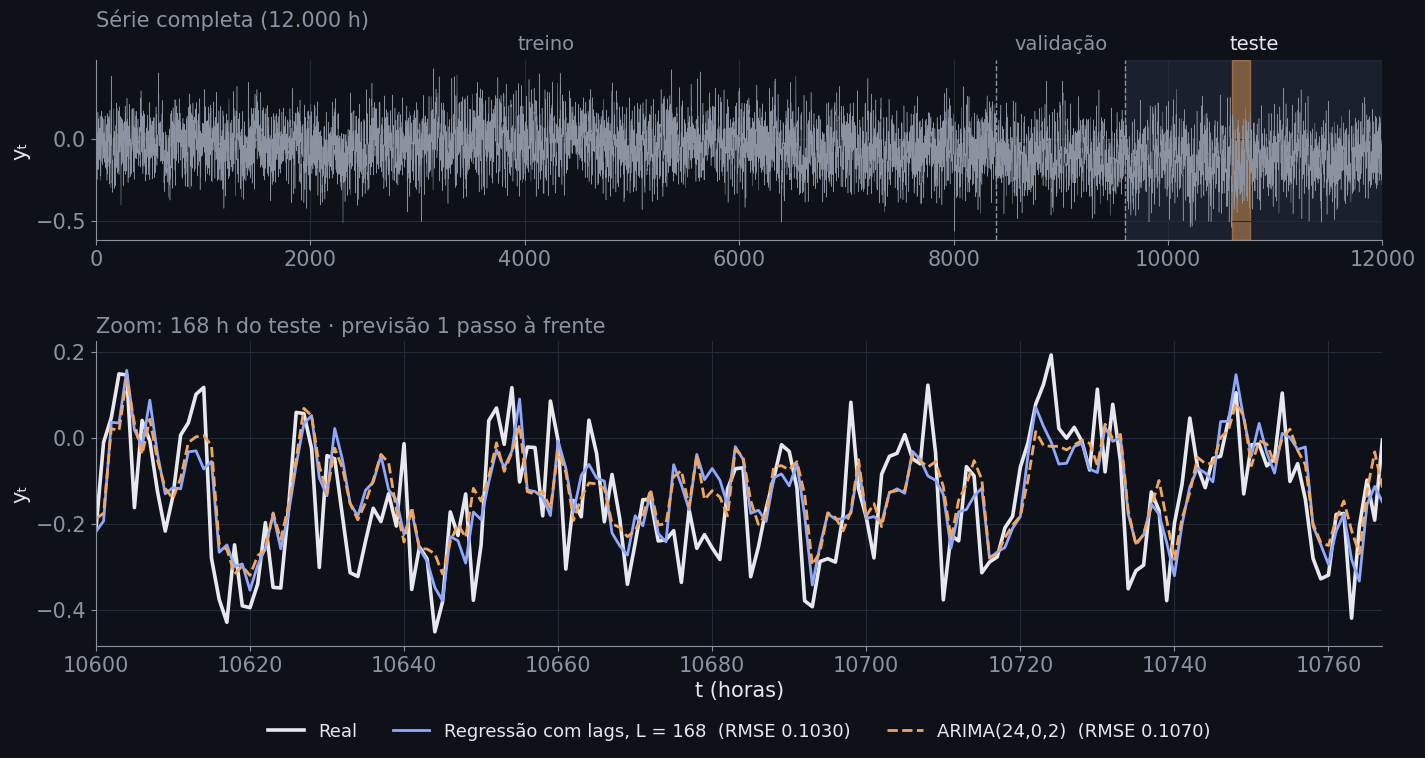

In [4]:
LR_L = 168                                   # qual regressão mostrar no zoom
p_lr, p_ar = prev[f"linear_regression__{LR_L}"], prev["arima__None"]
z = slice(ZOOM_INICIO, ZOOM_INICIO + ZOOM_HORAS)
tz = t_teste[z]

fig, (a0, a1) = plt.subplots(2, 1, figsize=(16.6, 7.6), gridspec_kw={"height_ratios": [1, 1.7], "hspace": 0.42})

# painel de cima: série completa
a0.plot(np.arange(n), serie, color=MUTED, lw=0.35)
for ini, fim, nome in [(0, train_end, "treino"), (train_end, val_end, "validação"), (val_end, n, "teste")]:
    a0.axvspan(ini, fim, color=ACC if nome == "teste" else GRID, alpha=0.10 if nome == "teste" else 0.0)
    a0.text((ini + fim) / 2, 1.04, nome, transform=a0.get_xaxis_transform(), ha="center", va="bottom", color=FG if nome == "teste" else MUTED, fontsize=14)
for x in (train_end, val_end):
    a0.axvline(x, color=MUTED, lw=1, ls="--")
a0.axvspan(tz[0], tz[-1], color=ORANGE, alpha=0.45)
a0.set(xlim=(0, n), ylabel="yₜ")
a0.set_title("Série completa (12.000 h)", loc="left", fontsize=15, color=MUTED, pad=24)

# painel de baixo: zoom
a1.plot(tz, y_real[z], color=FG, lw=2.6, label="Real")
a1.plot(tz, p_lr[z], color=ACC, lw=2.0, label=f"Regressão com lags, L = {LR_L}  (RMSE {rmse(y_real, p_lr):.4f})")
a1.plot(tz, p_ar[z], color=ORANGE, lw=2.0, ls="--", label=f"ARIMA(24,0,2)  (RMSE {rmse(y_real, p_ar):.4f})")
a1.set(xlim=(tz[0], tz[-1]), xlabel="t (horas)", ylabel="yₜ")
a1.set_title(f"Zoom: {ZOOM_HORAS} h do teste · previsão 1 passo à frente", loc="left", fontsize=15, color=MUTED)
a1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=13)
salvar(fig, "classicos_previsao_completa"); plt.show()

**Como ler:** os dois modelos seguem o formato geral da série, porque o lag 1 e o lag 24 carregam muita informação. Nenhum acerta os "picos" exatos: eles vêm do ruído εₜ, que é imprevisível. A diferença entre os modelos é pequena ponto a ponto e aparece na média (RMSE). Por isso o gráfico de RMSE × contexto (seção 5) é o que mostra o efeito do contexto com clareza.

## 4. Zoom por contexto (regressão com lags)

Um painel para cada contexto testado, no mesmo trecho. O título traz o RMSE do teste inteiro.

figura salva em results/figuras/classicos_zoom_por_contexto.png


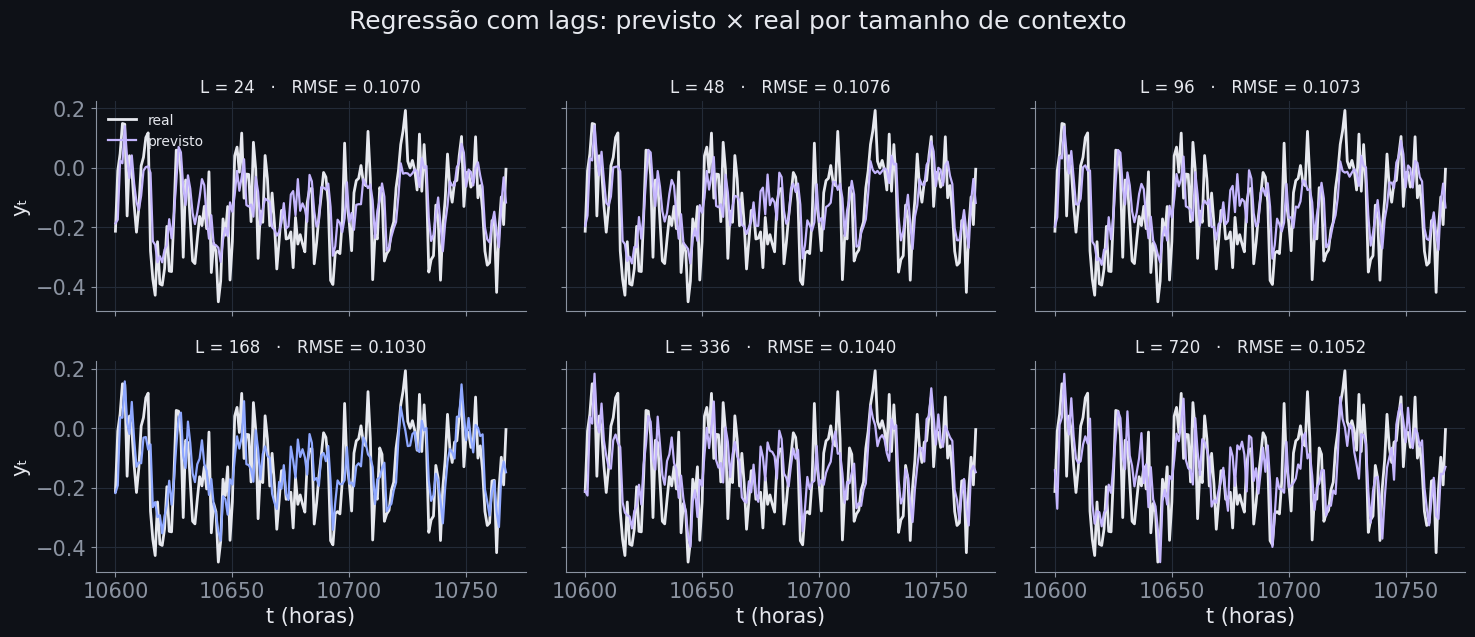

In [5]:
ctxs = sorted(int(c) for c in metricas.loc[metricas.model == "linear_regression", "context_length"])
fig, axs = plt.subplots(2, 3, figsize=(15, 6.4), sharex=True, sharey=True)
for ax, L in zip(axs.flat, ctxs):
    p = prev[f"linear_regression__{L}"]
    ax.plot(tz, y_real[z], color=FG, lw=2.0, label="real")
    ax.plot(tz, p[z], color=ACC if L == 168 else ACC2, lw=1.6, label="previsto")
    ax.set_title(f"L = {L}   ·   RMSE = {rmse(y_real, p):.4f}", fontsize=12)
axs[0, 0].legend(loc="upper left", fontsize=10)
for ax in axs[1]: ax.set_xlabel("t (horas)")
for ax in axs[:, 0]: ax.set_ylabel("yₜ")
fig.suptitle("Regressão com lags: previsto × real por tamanho de contexto", y=1.0)
fig.tight_layout(); salvar(fig, "classicos_zoom_por_contexto"); plt.show()

## 5. RMSE × contexto

O resumo numérico do comportamento: o erro cai quando o contexto alcança o lag 168 e volta a subir quando a regressão precisa estimar parâmetros demais. O ARIMA não usa janela de contexto, por isso aparece como **linha horizontal de referência** e não como mais uma curva.

figura salva em results/figuras/classicos_rmse_contexto.png


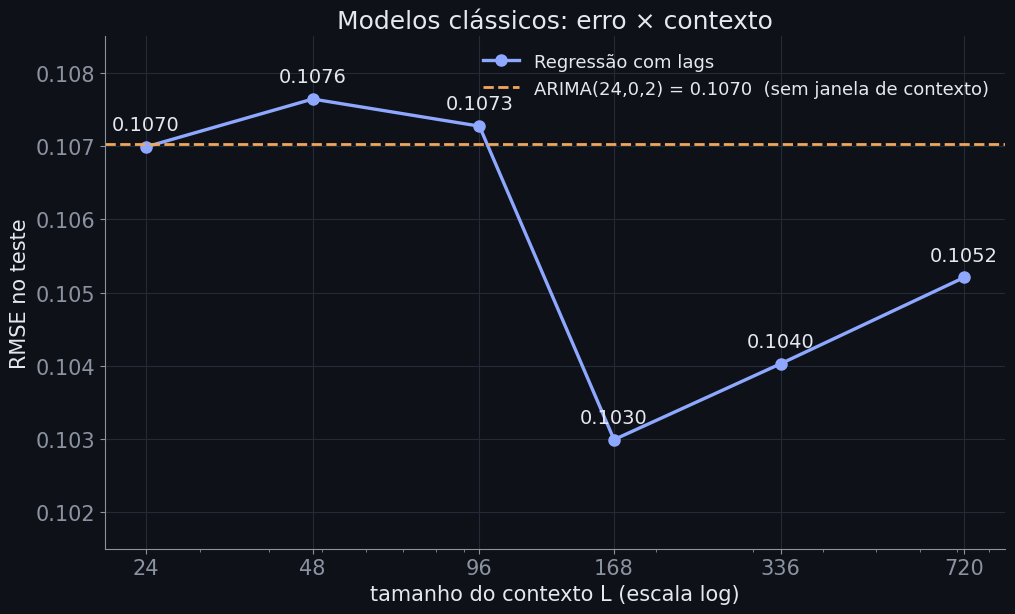

In [6]:
lr = metricas[metricas.model == "linear_regression"].sort_values("context_length")
arima = float(metricas.loc[metricas.model == "arima", "rmse"].iloc[0])

fig, ax = plt.subplots(figsize=(10.4, 6.4))
ax.plot(lr.context_length, lr.rmse, "-o", color=ACC, lw=2.4, ms=8, label="Regressão com lags")
for L, r in zip(lr.context_length, lr.rmse):
    ax.annotate(f"{r:.4f}", (L, r), xytext=(0, 12), textcoords="offset points", ha="center", fontsize=14)
ax.axhline(arima, color=ORANGE, ls="--", lw=2.0, label=f"ARIMA(24,0,2) = {arima:.4f}  (sem janela de contexto)")
ax.set_xscale("log"); ax.set_xticks(lr.context_length); ax.set_xticklabels(lr.context_length.astype(int))
ax.set(xlabel="tamanho do contexto L (escala log)", ylabel="RMSE no teste", title="Modelos clássicos: erro × contexto")
ax.set_ylim(0.1015, 0.1085)
ax.legend(loc="upper right", fontsize=13)
fig.tight_layout(); salvar(fig, "classicos_rmse_contexto"); plt.show()

## 6. O que a regressão aprendeu

Com L = 720 a regressão estima **um coeficiente por lag**. Comparando com os coeficientes verdadeiros do processo gerador (círculos), dá para ver se ela "encontrou" as dependências.

figura salva em results/figuras/classicos_coeficientes.png


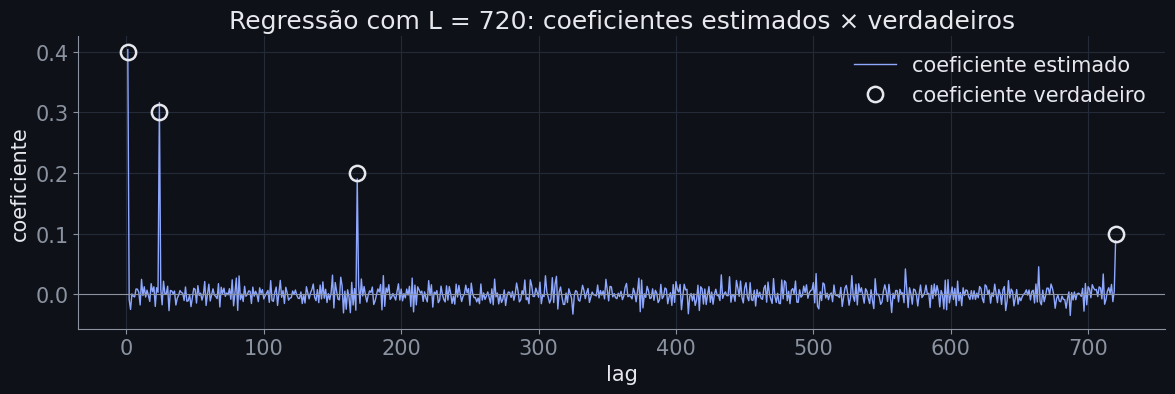

lag    1: verdadeiro = 0.400   estimado = +0.404
lag   24: verdadeiro = 0.300   estimado = +0.316
lag  168: verdadeiro = 0.200   estimado = +0.191
lag  720: verdadeiro = 0.100   estimado = +0.088

nos outros 716 lags o coeficiente deveria ser 0; desvio-padrão estimado = 0.013


In [7]:
L = 720
coef = prev[f"linear_regression__{L}__coef"][::-1]      # índice 0 = lag 1
lags = np.arange(1, L + 1)
verdade = {d["lag"]: d["coefficient"] for d in cfg["data"]["dependencies"]}

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(lags, coef, color=ACC, lw=1.0, label="coeficiente estimado")
ax.plot(list(verdade), list(verdade.values()), "o", ms=11, mfc="none", mec=FG, mew=1.8, label="coeficiente verdadeiro")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set(xlabel="lag", ylabel="coeficiente", title=f"Regressão com L = {L}: coeficientes estimados × verdadeiros")
ax.legend(loc="upper right")
fig.tight_layout(); salvar(fig, "classicos_coeficientes"); plt.show()

for lag, v in verdade.items():
    print(f"lag {lag:4d}: verdadeiro = {v:.3f}   estimado = {coef[lag-1]:+.3f}")
ruido = np.delete(coef, [l - 1 for l in verdade])
print(f"\nnos outros {len(ruido)} lags o coeficiente deveria ser 0; desvio-padrão estimado = {ruido.std():.3f}")

**Como ler:** os picos aparecem exatamente nos lags 1, 24, 168 e 720. Nos demais 716 lags os coeficientes deveriam ser zero, mas oscilam um pouco: é o **custo de estimação** de ter 721 parâmetros, que explica por que L = 720 não foi o melhor contexto.

## Figuras geradas

| arquivo | uso sugerido |
|---|---|
| `classicos_previsao_completa.png` | slide de resultados: série completa + zoom previsto × real |
| `classicos_zoom_por_contexto.png` | mostrar o efeito do contexto visualmente |
| `classicos_rmse_contexto.png` | slide "RMSE × context length" |
| `classicos_coeficientes.png` | discussão: o que o modelo linear aprende |